# IS 4487 Assignment 9: Customer Segmentation with Clustering

In this assignment, you will:
- Apply unsupervised learning to explore patterns in hotel booking behavior
- Use K-Means and Gaussian Mixture Models (GMM) for customer segmentation
- Evaluate model quality with metrics like Silhouette Score and Davies-Bouldin Index
- Connect clustering to actionable business insights

## Why This Matters

Businesses like hotels and travel platforms (e.g., Airbnb or Expedia) rely on customer segmentation to tailor promotions, pricing strategies, and service levels. Unlike supervised models, clustering helps uncover patterns when no labels exist—an ideal tool when entering new markets or analyzing unstructured customer behavior.

<a href="https://colab.research.google.com/github/Stan-Pugsley/is_4487_base/blob/main/Assignments/assignment_09_clustering.ipynb" target="_parent">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>


## Dataset Description: Hotel Bookings

This dataset contains booking information for two types of hotels: a **city hotel** and a **resort hotel**. Each record corresponds to a single booking and includes various details about the reservation, customer demographics, booking source, and whether the booking was canceled.

**Source**: [GitHub - TidyTuesday: Hotel Bookings](https://github.com/rfordatascience/tidytuesday/blob/master/data/2020/2020-02-11/readme.md)

### Key Use Cases
- Understand customer booking behavior
- Explore factors related to cancellations
- Segment guests based on booking characteristics
- Compare city vs. resort hotel performance

### Data Dictionary

| Variable | Type | Description |
|----------|------|-------------|
| `hotel` | character | Hotel type: City or Resort |
| `is_canceled` | integer | 1 = Canceled, 0 = Not Canceled |
| `lead_time` | integer | Days between booking and arrival |
| `arrival_date_year` | integer | Year of arrival |
| `arrival_date_month` | character | Month of arrival |
| `stays_in_weekend_nights` | integer | Nights stayed on weekends |
| `stays_in_week_nights` | integer | Nights stayed on weekdays |
| `adults` | integer | Number of adults |
| `children` | integer | Number of children |
| `babies` | integer | Number of babies |
| `meal` | character | Type of meal booked |
| `country` | character | Country code of origin |
| `market_segment` | character | Booking source (e.g., Direct, Online TA) |
| `distribution_channel` | character | Booking channel used |
| `is_repeated_guest` | integer | 1 = Repeated guest, 0 = New guest |
| `previous_cancellations` | integer | Past booking cancellations |
| `previous_bookings_not_canceled` | integer | Past bookings not canceled |
| `reserved_room_type` | character | Initially reserved room type |
| `assigned_room_type` | character | Room type assigned at check-in |
| `booking_changes` | integer | Number of booking modifications |
| `deposit_type` | character | Deposit type (No Deposit, Non-Refund, etc.) |
| `agent` | character | Agent ID who made the booking |
| `company` | character | Company ID (if booking through company) |
| `days_in_waiting_list` | integer | Days on the waiting list |
| `customer_type` | character | Booking type: Contract, Transient, etc. |
| `adr` | float | Average Daily Rate (price per night) |
| `required_car_parking_spaces` | integer | Requested parking spots |
| `total_of_special_requests` | integer | Number of special requests made |
| `reservation_status` | character | Final status (Canceled, No-Show, Check-Out) |
| `reservation_status_date` | date | Date of the last status update |

This dataset is ideal for classification, segmentation, and trend analysis exercises.

## 1. Setup and Load Data

### Business framing:  

### Do the following:
Before we can cluster or segment anything, we need clean, accessible data in a usable format.

- Import the necessary Python libraries
- Import data from the hotels dataset into a dataframe (in GitHub go to the DataSets folder and look for `hotels.csv`)
- Display the first few rows
- Show summary statistics for the dataframe

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score


url = "https://raw.githubusercontent.com/Stan-Pugsley/is_4487_base/main/DataSets/hotels.csv"
df = pd.read_csv(url)

print("--- First 5 Rows ---")
display(df.head())

print("\n--- Summary Statistics ---")
display(df.describe(include='all'))

--- First 5 Rows ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



--- Summary Statistics ---


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
count,9404,9404.000000,9404.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404.000000,9404.000000,...,9404,7069.000000,1011.000000,9404.000000,9404,9404.000000,9404.000000,9404.000000,9404,9404
unique,1,NaN,NaN,NaN,12,NaN,NaN,NaN,NaN,NaN,...,3,NaN,NaN,NaN,4,NaN,NaN,NaN,3,713
top,Resort Hotel,NaN,NaN,NaN,October,NaN,NaN,NaN,NaN,NaN,...,No Deposit,NaN,NaN,NaN,Transient,NaN,NaN,NaN,Check-Out,2015-11-15
freq,9404,NaN,NaN,NaN,1610,NaN,NaN,NaN,NaN,NaN,...,8816,NaN,NaN,NaN,7031,NaN,NaN,NaN,7069,124
mean,NaN,0.248299,79.326244,2015.156104,NaN,37.026584,15.515313,1.155040,3.078690,1.864738,...,NaN,200.990946,219.550940,1.019034,NaN,86.843614,0.144938,0.613143,NaN,NaN
std,NaN,0.432049,87.584146,0.443661,NaN,11.083421,9.025545,1.124304,2.379227,1.198565,...,NaN,80.330753,104.296474,10.137928,NaN,53.759940,0.353264,0.835930,NaN,NaN
min,NaN,0.000000,0.000000,2015.000000,NaN,1.000000,1.000000,0.000000,0.000000,0.000000,...,NaN,1.000000,9.000000,0.000000,NaN,-6.380000,0.000000,0.000000,NaN,NaN
25%,NaN,0.000000,8.000000,2015.000000,NaN,31.000000,7.000000,0.000000,1.000000,2.000000,...,NaN,156.000000,135.000000,0.000000,NaN,45.000000,0.000000,0.000000,NaN,NaN
50%,NaN,0.000000,48.000000,2015.000000,NaN,38.000000,16.000000,1.000000,3.000000,2.000000,...,NaN,240.000000,223.000000,0.000000,NaN,71.550000,0.000000,0.000000,NaN,NaN
75%,NaN,0.000000,118.000000,2015.000000,NaN,45.000000,23.000000,2.000000,5.000000,2.000000,...,NaN,241.000000,286.000000,0.000000,NaN,120.600000,0.000000,1.000000,NaN,NaN


### Reflection:
1. What stands out in the initial preview? Any columns or rows that seem unusual?

### ✍️ Your Response: 🔧
1. The room rate adr drops down to -6.38, which is unusual because prices should not be negative.
2. Some bookings were made over 700 days in advance, which is extremely early.
3. Columns like agent and company have a lot of missing values, likely because many guests book directly.

## 2. Select and Prepare Features

### Business framing:  

A hotel might want to group guests based on how long they stay, how far in advance they book, or how likely they are to make special requests. You need to pick variables that represent meaningful guest behavior.

### Do the following:
- 2.1 Choose 3–5 numeric features related to customer behavior
- 2.2 Perform basic data preparation - remove outliers, remove duplicates, correct any datatypes that need adjustment
- 2.3 Drop missing values if needed
- 2.4 Standardize using `StandardScaler` for any large values  (over 100)

In [9]:
df['total_stay_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

features = ['lead_time', 'total_stay_nights', 'adr', 'total_of_special_requests']
cleaned_df = df[features].copy()

cleaned_df = cleaned_df[cleaned_df['adr'] >= 0]


cleaned_df = cleaned_df.drop_duplicates()


cleaned_df = cleaned_df.dropna()


scaler = StandardScaler()
scaled_features = scaler.fit_transform(cleaned_df)


df_scaled = pd.DataFrame(scaled_features, columns=features)

print("Original dataset shape:", df.shape)
print("Cleaned and prepared unique dataset shape:", cleaned_df.shape)
print("\nFirst few rows of the scaled features:")
display(df_scaled.head())

Original dataset shape: (9404, 33)
Cleaned and prepared unique dataset shape: (6541, 4)

First few rows of the scaled features:


,lead_time,total_stay_nights,adr,total_of_special_requests
0,3.652402,-1.406827,-1.735584,-0.861793
1,8.933786,-1.406827,-1.735584,-0.861793
2,-0.826747,-1.108562,-0.391639,-0.861793
3,-0.746523,-1.108562,-0.391639,-0.861793
4,-0.733152,-0.810298,0.020504,0.281149


### Reflection:
1. What features did you select and why?
2. What kinds of patterns or segments do you expect to find?

### ✍️ Your Response: 🔧
1. We selected lead_time, total_stay_nights, adr, and total_of_special_requests. These capture key behaviors when they book, how long they stay, how much they spend, and how many special needs they have.
2. We expect to find groups like:
   - People booking at the last minute for quick, low-maintenance stays.
   - Customers booking far in advance, staying longer, paying higher rates, and making multiple special requests.

## 3. Apply K-Means Clustering

### Business framing:  

Let’s say you’re working with the hotel’s marketing manager. She wants to group guests into a few clear types to target email campaigns. K-Means is a fast, simple way to try this.

### Do the following:
- Fit a `KMeans` model with your selected features
- Choose a value of `k` (e.g. 3, 4, or 5)
- Predict clusters and assign a cluster number to each guest
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

Much of this assignment has already been covered in the lab. Please be sure to complete the lab before the assignment.

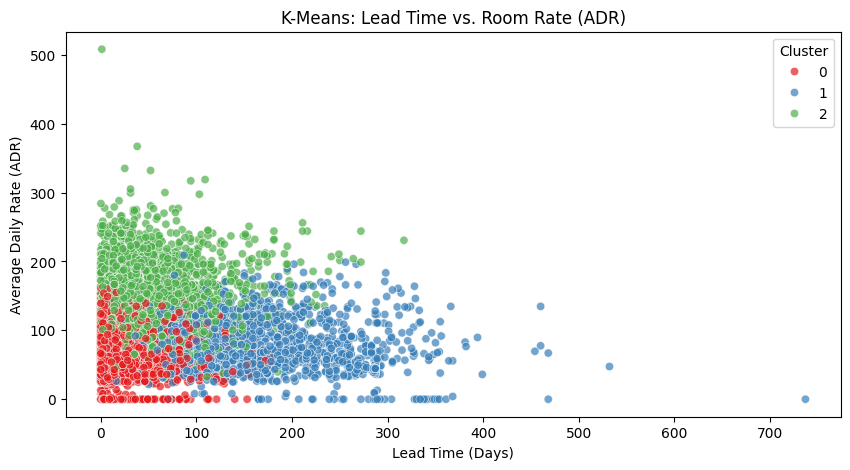

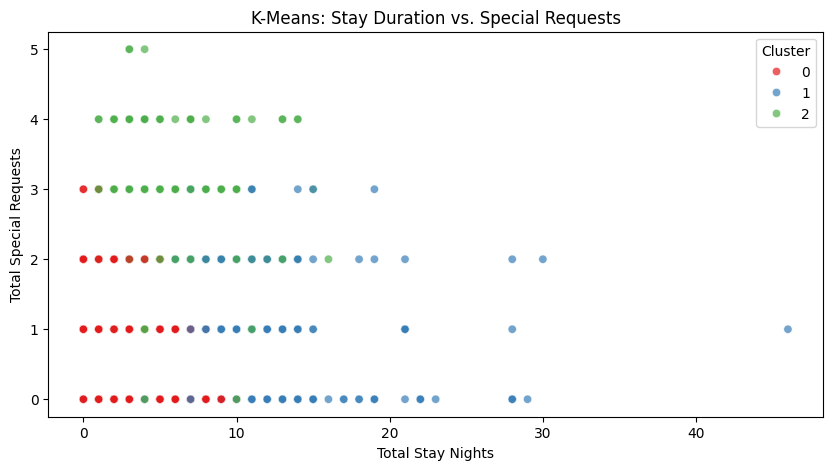


--- Average Values for Each Customer Cluster ---


,lead_time,total_stay_nights,adr,total_of_special_requests
cluster,,,,
0,25.771546,2.767784,65.135065,0.488372
1,162.825611,7.967825,80.312915,0.504505
2,59.064954,5.030053,154.276389,1.318468


In [10]:

kmeans = KMeans(n_clusters=3, random_state=42)
cleaned_df['cluster'] = kmeans.fit_predict(df_scaled)


plt.figure(figsize=(10, 5))
sns.scatterplot(data=cleaned_df, x='lead_time', y='adr', hue='cluster', palette='Set1', alpha=0.7)
plt.title('K-Means: Lead Time vs. Room Rate (ADR)')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate (ADR)')
plt.legend(title='Cluster')
plt.show()


plt.figure(figsize=(10, 5))
sns.scatterplot(data=cleaned_df, x='total_stay_nights', y='total_of_special_requests', hue='cluster', palette='Set1', alpha=0.7)
plt.title('K-Means: Stay Duration vs. Special Requests')
plt.xlabel('Total Stay Nights')
plt.ylabel('Total Special Requests')
plt.legend(title='Cluster')
plt.show()


summary = cleaned_df.groupby('cluster').mean()
print("\n--- Average Values for Each Customer Cluster ---")
display(summary)


1. What k value did you choose, and how did you decide?

2. For each cluster answer the following what types of customers seem to show up in the cluster?  which variables are most prominent or important for that cluster?  

### ✍️ Your Response: 🔧
1. We chose k=3 because it creates three simple, easy to understand customer groups.

2.  Book late, stay for a short time, and pay cheap room rates.
   - Group 1: Book way in advance, stay the longest, and pay average room rates.
   - Group 2: Pay the highest room rates and make the most special requests.

## 4. Apply Gaussian Mixture Model (GMM)

### Business framing:  

Not all guests fit neatly into one cluster. GMM lets us capture uncertainty — useful if customers behave similarly across groups.

### Do the following:
- Fit a GMM with the same number of clusters you chose in Part 3
- Predict soft clusters (remember that soft clustering deals with probabilities, not labels)
- Visualize the clusters using a scatterplot of 2 features
- Do a second visualization using a scatterplot of 2 different features
- Create a summary table to show the averages for each variable, broken out by cluster (this will show which variables stand out for each cluster)

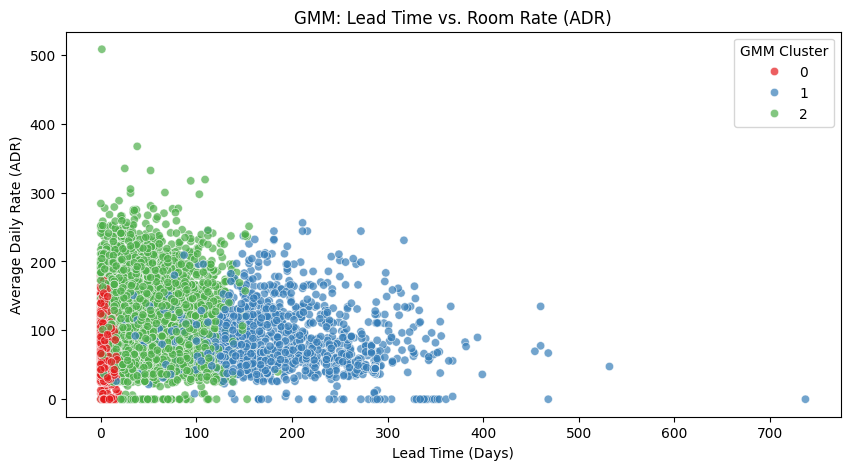

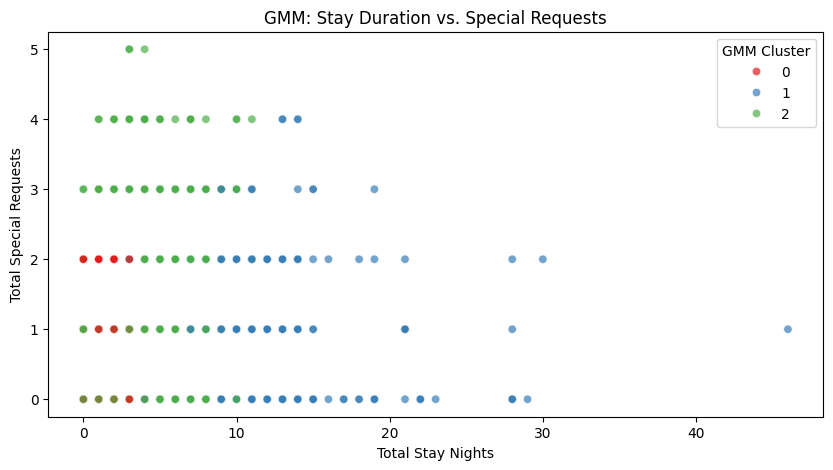


--- Average Values for Each GMM Customer Cluster ---


,lead_time,total_stay_nights,adr,total_of_special_requests
gmm_cluster,,,,
0,4.623943,1.735198,64.308426,0.542615
1,178.216703,7.889129,86.376415,0.628510
2,54.104564,4.765422,114.720470,0.892116


In [12]:
gmm = GaussianMixture(n_components=3, random_state=42)
gmm_labels = gmm.fit_predict(df_scaled)

soft_probabilities = gmm.predict_proba(df_scaled)


cleaned_df['gmm_cluster'] = gmm_labels
for i in range(3):
    cleaned_df[f'gmm_prob_cluster_{i}'] = soft_probabilities[:, i]


plt.figure(figsize=(10, 5))
sns.scatterplot(data=cleaned_df, x='lead_time', y='adr', hue='gmm_cluster', palette='Set1', alpha=0.7)
plt.title('GMM: Lead Time vs. Room Rate (ADR)')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Average Daily Rate (ADR)')
plt.legend(title='GMM Cluster')
plt.show()


plt.figure(figsize=(10, 5))
sns.scatterplot(data=cleaned_df, x='total_stay_nights', y='total_of_special_requests', hue='gmm_cluster', palette='Set1', alpha=0.7)
plt.title('GMM: Stay Duration vs. Special Requests')
plt.xlabel('Total Stay Nights')
plt.ylabel('Total Special Requests')
plt.legend(title='GMM Cluster')
plt.show()


columns_to_summarize = ['lead_time', 'total_stay_nights', 'adr', 'total_of_special_requests', 'gmm_cluster']
gmm_summary = cleaned_df[columns_to_summarize].groupby('gmm_cluster').mean()
print("\n--- Average Values for Each GMM Customer Cluster ---")
display(gmm_summary)

### Reflection:
1. How did the GMM results compare to KMeans?
2. What business questions might GMM help answer better?

### ✍️ Your Response: 🔧
1. GMM and K-Means produced similar overall groupings, but GMM isolated an extreme immediate booker segment compared to the more spread out last minute cluster in K-Means.
2. GMM uses soft clustering. This is highly useful for identifying borderline customers who exhibit behaviors of multiple segments, allowing for highly targeted upselling or tailored marketing campaigns.

## 5. Evaluate Your Models

### Business framing:  

In business, models should be both useful and reliable. You’ll compare model quality using standard evaluation metrics.

### Do the following:
- 5.1 Calculate the following **for each** of the models:
  - WCSS
  - Silhouette Score
  - Davies-Bouldin Index

  **NOTE:** This step may take up to 5 minutes.  It is a lot of computation time.  Please be patient.  Or you can limit the scores to using a random sample of 10K rows.

**Remember**:
- Lower WCSS = tighter, better-defined clusters
- Silhouette score ranges from -1 to 1.  Higher values = better clustering
- Lower Davies-Boulding Index = better clustering

In [13]:
kmeans_wcss = kmeans.inertia_
kmeans_silhouette = silhouette_score(df_scaled, kmeans.labels_)
kmeans_db_index = davies_bouldin_score(df_scaled, kmeans.labels_)


gmm_centers = []
for i in range(3):
    gmm_centers.append(df_scaled.values[gmm_labels == i].mean(axis=0))
gmm_centers = np.array(gmm_centers)

gmm_wcss = 0
for i in range(3):
    cluster_points = df_scaled.values[gmm_labels == i]
    gmm_wcss += np.sum((cluster_points - gmm_centers[i]) ** 2)

gmm_silhouette = silhouette_score(df_scaled, gmm_labels)
gmm_db_index = davies_bouldin_score(df_scaled, gmm_labels)

evaluation_results = pd.DataFrame({
    'Metric': ['WCSS (Lower is Better)', 'Silhouette Score (Higher is Better)', 'Davies-Bouldin Index (Lower is Better)'],
    'K-Means': [kmeans_wcss, kmeans_silhouette, kmeans_db_index],
    'GMM': [gmm_wcss, gmm_silhouette, gmm_db_index]
})

print("--- Model Evaluation Metrics Comparison ---")
display(evaluation_results)

--- Model Evaluation Metrics Comparison ---


,Metric,K-Means,GMM
0,WCSS (Lower is Better),15718.120531,18309.440354
1,Silhouette Score (Higher is Better),0.270219,0.132189
2,Davies-Bouldin Index (Lower is Better),1.392393,1.738284


### Reflection:
5.2. Which model performed better on the metrics?

5.3. Would you recommend KMeans or GMM for a business analyst? Why?

### ✍️ Your Response: 🔧
5.2. K-Means performed better across all three metrics. It achieved a lower WCSS, a higher Silhouette Score, and a lower Davies-Bouldin Index.

5.3. I would recommend K-Means for a business analyst. It is much easier to explain to stakeholders, runs faster, and provides simpler, non-overlapping customer segments that are directly actionable for marketing campaigns.

## 6. Business Interpretation

### Business framing:  

What do these clusters mean in the real world? Could they represent solo travelers, families, or bargain shoppers?

### Do the following:
- Display the characteristics of each cluster (e.g. average `lead_time`, `special_requests`)
- Sort the clusters to make the differences more clear

In [14]:

kmeans_interpretation = cleaned_df.groupby('cluster')[features].mean()


sorted_interpretation = kmeans_interpretation.sort_values(by='adr')

print("--- Sorted Customer Cluster Characteristics (Sorted by Room Rate / ADR) ---")
display(sorted_interpretation)

--- Sorted Customer Cluster Characteristics (Sorted by Room Rate / ADR) ---


,lead_time,total_stay_nights,adr,total_of_special_requests
cluster,,,,
0,25.771546,2.767784,65.135065,0.488372
1,162.825611,7.967825,80.312915,0.504505
2,59.064954,5.030053,154.276389,1.318468


### Reflection:
1. What do the segments represent in terms of guest behavior?
2. How could the hotel tailor services or promotions to each group?

### ✍️ Your Response: 🔧
1.
Group 0: Budget-conscious travelers who book last-minute for short stays with very low room rates and minimal requests.

Group 1 : Guests who plan far in advance for extended stays, paying moderate room rates.

Group 2: High-spending guests paying the highest rates who require multiple special accommodations.

2.
   Group 0: Target with last-minute flash sales, mobile-only discounts, and quick check-in options.
   
   Group 1: Offer early-bird booking discounts, weekly stay packages, or vacation planning guides.
   
   Group 2: Provide premium room upgrades, VIP concierge services, and pre-arrival emails to collect their special requests.

## 7. Final Reflection

### Business framing:  

Many teams ask for "segmentation" without knowing how it works. You now have hands-on experience with two clustering techniques and how to present the results.

### Reflection:
1. What was most challenging about unsupervised learning?
2. When would you use clustering instead of supervised models?
3. How would you explain the value of clustering to a non-technical manager?
4. How does this relate to your customized learning outcome you created in canvas?


### ✍️ Your Response: 🔧
1. The lack of predefined correct labels, which makes evaluating cluster quality and defining optimal segment boundaries more subjective.

2. Use clustering when exploring unlabeled dataset patterns or discovering natural customer groups, use supervised models when trying to predict a specific target target.

3. Clustering is like organizing a messy closet of customers into distinct hangers based on shared behaviors. It lets us target each group with tailored deals rather than treating everyone the same.

4. This directly applies my learning goal of understanding how machine learning models translate raw behavioral metrics into clear, actionable business segments.

## Submission Instructions

✅ **Before submitting:**
- Make sure all code cells are run and outputs are visible  
- All markdown questions are answered thoughtfully  
- Submit the assignment as an **HTML file** on Canvas


In [16]:
!jupyter nbconvert --to html "/content/assignment_09_clustering.ipynb"

[NbConvertApp] Converting notebook /content/assignment_09_clustering.ipynb to html
[NbConvertApp] WARNING | Alternative text is missing on 4 image(s).
[NbConvertApp] Writing 912409 bytes to /content/assignment_09_clustering.html
